In [12]:
import re
import os
import sys
import random
import pymorphy3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

path = os.getcwd().replace("\\notebooks", "")
sys.path.append(path)

from src.preprocessing import preprocessing


from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    pairwise_distances,
)


In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

df = preprocessing(path + "\\data\\datasets.csv")
neg_df = df[df["sentiment"] == 2].copy().reset_index(drop=True)

print(f"Всего негативных отзывов: {len(neg_df):,}")
neg_df.head(3)


Всего негативных отзывов: 55,310


,n,text,sentiment,clean_review
0,13019,Не было. Это пиздеш ТСа.\r\n,2,не было это пиздеш тса
1,26422,Очень вкусно готовят и цены приемлемые ! Отзы...,2,очень вкусно готовят и цены приемлемые отзывчи...
2,22919,До качественной медицины нам далеко\r\nПробова...,2,до качественной медицины нам далеко пробовала ...


In [3]:

with open(path + "\\data\\stopswords.txt", "r", encoding="utf-8") as f:
    stopwords = [line.strip() for line in f if line.strip()]

TOKEN_RE = re.compile(r"[A-Za-zА-Яа-яЁё]+")
morph = pymorphy3.MorphAnalyzer()

def safe_lemma(token: str) -> str:
    token = token.lower().replace("ё", "е")
    if not token:
        return token
    try:
        return morph.parse(token)[0].normal_form
    except Exception:
        return token

# Лемматизируем стоп-слова тоже, чтобы фильтрация была согласованной
stopwords_lemmas = {safe_lemma(word) for word in stopwords}

def normalize_text(text: str):
    if not isinstance(text, str):
        return []
    tokens = TOKEN_RE.findall(text.lower())
    lemmas = []
    for token in tokens:
        token = token.replace("ё", "е")
        if len(token) < 2:
            continue
        lemma = safe_lemma(token)
        if len(lemma) < 2:
            continue
        if lemma in stopwords_lemmas:
            continue
        lemmas.append(lemma)
    return lemmas

test_words = ["врачи", "врач", "врача", "врачей", "лечить", "лечит", "лечения", "деньги", "денег"]
[(w, safe_lemma(w)) for w in test_words]


[('врачи', 'врач'),
 ('врач', 'врач'),
 ('врача', 'врач'),
 ('врачей', 'врач'),
 ('лечить', 'лечить'),
 ('лечит', 'лечить'),
 ('лечения', 'лечение'),
 ('деньги', 'деньга'),
 ('денег', 'деньга')]

In [4]:
vectorizer = TfidfVectorizer(
    tokenizer=normalize_text,
    token_pattern=None,     
    lowercase=False,         
    max_features=20000,
    min_df=5,
    max_df=0.8,
    ngram_range=(1, 2),
    sublinear_tf=True,
)

X = vectorizer.fit_transform(neg_df["clean_review"].fillna(""))
print("TF-IDF shape:", X.shape)


TF-IDF shape: (55310, 20000)


In [5]:
svd = TruncatedSVD(n_components=min(100, X.shape[1] - 1), random_state=RANDOM_STATE)
normalizer = Normalizer(copy=False)
X_reduced = make_pipeline(svd, normalizer).fit_transform(X)

print("Reduced shape:", X_reduced.shape)
print("Explained variance ratio:", round(float(svd.explained_variance_ratio_.sum()), 4))


Reduced shape: (55310, 100)
Explained variance ratio: 0.1053


In [6]:
def evaluate_k_range(X_sparse, X_dense, candidate_k, sample_size=3000, random_state=42):
    n = X_dense.shape[0]
    sample_size = min(sample_size, n)
    sample_idx = np.random.RandomState(random_state).choice(n, size=sample_size, replace=False)
    X_sample = X_dense[sample_idx]

    rows = []
    for k in candidate_k:
        model = MiniBatchKMeans(
            n_clusters=k,
            random_state=random_state,
            n_init=10,
            batch_size=1024,
        )
        labels = model.fit_predict(X_dense)
        sample_labels = labels[sample_idx]

        sil = silhouette_score(X_sample, sample_labels, metric="euclidean")
        ch = calinski_harabasz_score(X_dense, labels)
        db = davies_bouldin_score(X_dense, labels)

        rows.append(
            {
                "k": k,
                "silhouette": sil,
                "calinski_harabasz": ch,
                "davies_bouldin": db,
                "inertia": model.inertia_,
            }
        )
        print(
            f"k={k:>2} | silhouette={sil:.4f} | "
            f"calinski_harabasz={ch:,.0f} | davies_bouldin={db:.4f}"
        )

    metrics_df = pd.DataFrame(rows)

    metrics_df["rank_silhouette"] = metrics_df["silhouette"].rank(ascending=False, method="min")
    metrics_df["rank_ch"] = metrics_df["calinski_harabasz"].rank(ascending=False, method="min")
    metrics_df["rank_db"] = metrics_df["davies_bouldin"].rank(ascending=True, method="min")
    metrics_df["rank_sum"] = (
        metrics_df["rank_silhouette"]
        + metrics_df["rank_ch"]
        + metrics_df["rank_db"]
    )

    return metrics_df.sort_values(["rank_sum", "silhouette", "calinski_harabasz"], ascending=[True, False, False])

candidate_k = list(range(4, 21))
metrics_df = evaluate_k_range(X, X_reduced, candidate_k, sample_size=3000, random_state=RANDOM_STATE)
metrics_df


k= 4 | silhouette=0.0495 | calinski_harabasz=2,067 | davies_bouldin=4.3008
k= 5 | silhouette=0.0466 | calinski_harabasz=1,700 | davies_bouldin=4.2445
k= 6 | silhouette=0.0579 | calinski_harabasz=1,764 | davies_bouldin=3.7876
k= 7 | silhouette=0.0630 | calinski_harabasz=1,568 | davies_bouldin=3.6519
k= 8 | silhouette=0.0571 | calinski_harabasz=1,537 | davies_bouldin=4.1398
k= 9 | silhouette=0.0622 | calinski_harabasz=1,401 | davies_bouldin=4.0453
k=10 | silhouette=0.0611 | calinski_harabasz=1,390 | davies_bouldin=3.7324
k=11 | silhouette=0.0610 | calinski_harabasz=1,267 | davies_bouldin=3.6207
k=12 | silhouette=0.0589 | calinski_harabasz=1,198 | davies_bouldin=3.6106
k=13 | silhouette=0.0445 | calinski_harabasz=1,108 | davies_bouldin=3.8434
k=14 | silhouette=0.0560 | calinski_harabasz=1,143 | davies_bouldin=3.6973
k=15 | silhouette=0.0646 | calinski_harabasz=1,112 | davies_bouldin=3.5318
k=16 | silhouette=0.0656 | calinski_harabasz=1,037 | davies_bouldin=3.6585
k=17 | silhouette=0.0460 

,k,silhouette,calinski_harabasz,davies_bouldin,inertia,rank_silhouette,rank_ch,rank_db,rank_sum
3,7,0.062954,1567.896209,3.651941,41931.467878,5.0,4.0,8.0,17.0
16,20,0.072308,950.733829,3.281015,36963.322913,1.0,16.0,1.0,18.0
14,18,0.071337,1007.983448,3.495887,37418.259099,2.0,14.0,3.0,19.0
11,15,0.064556,1111.646944,3.531783,38261.712680,4.0,11.0,5.0,20.0
7,11,0.061036,1266.933983,3.620734,39874.863432,8.0,8.0,7.0,23.0
8,12,0.058946,1197.665143,3.610569,39617.510018,9.0,9.0,6.0,24.0
2,6,0.057895,1764.377390,3.787604,42425.294519,10.0,2.0,12.0,24.0
12,16,0.065588,1037.206439,3.658497,38303.531140,3.0,13.0,9.0,25.0
6,10,0.061053,1389.599721,3.732441,39945.243153,7.0,7.0,11.0,25.0
5,9,0.062244,1401.203534,4.045349,40736.940105,6.0,6.0,14.0,26.0


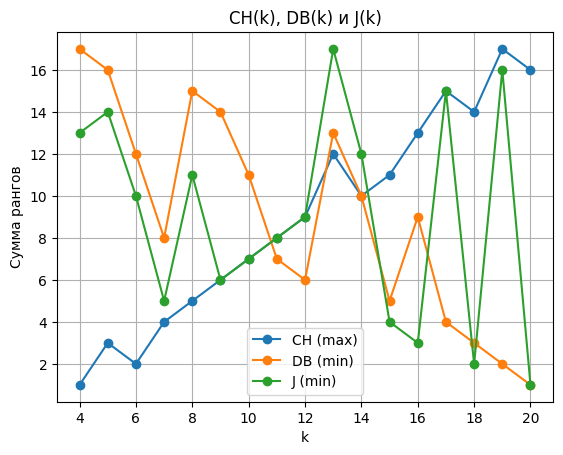

In [20]:
df = metrics_df.sort_values('k')

plt.figure()

# CH (максимум)
plt.plot(df['k'], df['rank_ch'], marker='o', label='CH (max)')

# DB (минимум)
plt.plot(df['k'], df['rank_db'], marker='o', label='DB (min)')
plt.plot(df['k'], df['rank_silhouette'], marker='o', label='J (min)')

plt.xlabel('k')
plt.ylabel('Сумма рангов')
plt.title('CH(k), DB(k) и J(k)')
plt.legend()
plt.grid()

plt.show()

In [ ]:
# best_k = int(metrics_df.iloc[0]["k"])
best_k = 15
print("Оптимальное число кластеров:", best_k)

# Финальная модель
kmeans = KMeans(
    n_clusters=best_k,
    random_state=RANDOM_STATE,
    n_init=20,
    max_iter=500,
)
neg_df["cluster"] = kmeans.fit_predict(X)


Оптимальное число кластеров: 7


In [8]:

def get_top_terms_per_cluster(kmeans_model, vectorizer, top_n=12):
    feature_names = np.array(vectorizer.get_feature_names_out())
    centers = kmeans_model.cluster_centers_
    result = {}

    for cluster_id in range(centers.shape[0]):
        top_indices = centers[cluster_id].argsort()[::-1][:top_n]
        result[cluster_id] = feature_names[top_indices].tolist()

    return result

cluster_terms = get_top_terms_per_cluster(kmeans, vectorizer, top_n=12)

print("Ключевые слова по кластерам:")
for cluster_id, terms in cluster_terms.items():
    print(f"Cluster {cluster_id}: {' | '.join(terms)}")


Ключевые слова по кластерам:
Cluster 0: зуб | клиника | пломба | врач | лечить | лечение | стоматолог | коронка | деньга | сделать | стоматология | лечить зуб
Cluster 1: больница | врач | отделение | ребёнок | лежать | палата | больной | скорый | отношение | медсестра | операция | сделать
Cluster 2: деньга | аптека | цена | работать | место | знать | отношение | делать | отзыв | работа | плохой | клиент
Cluster 3: ресторан | кухня | обслуживание | вкусный | понравиться | официант | еда | блюдо | вкусно | свадьба | уютный | место
Cluster 4: дозвониться | трубка | телефон | регистратура | невозможно | звонить | невозможно дозвониться | врач | вызвать врач | брать | врач дом | вызвать
Cluster 5: врач | приём | ребёнок | анализ | клиника | поликлиника | прийти | отношение | очередь | деньга | пациент | узи
Cluster 6: номер | отель | завтрак | окно | гостиница | кровать | комната | ночь | персонал | плюс | ванная | грязный


In [9]:

def detect_text_column(df: pd.DataFrame):
    candidates = [
        "Review", "review", "text", "comment", "raw_text",
        "clean_review", "clean_text", "content"
    ]
    for col in candidates:
        if col in df.columns:
            return col
    object_cols = [c for c in df.columns if df[c].dtype == "object"]
    return object_cols[0] if object_cols else None

TEXT_COL = detect_text_column(neg_df)
print("Текстовый столбец для примеров:", TEXT_COL)

def get_representative_reviews(df, X, kmeans_model, cluster_id, n=5, text_col=None):
    cluster_indices = np.where(df["cluster"].values == cluster_id)[0]
    if len(cluster_indices) == 0:
        return pd.DataFrame()

    cluster_vectors = X[cluster_indices]
    center = kmeans_model.cluster_centers_[cluster_id].reshape(1, -1)

    distances = pairwise_distances(cluster_vectors, center, metric="euclidean").ravel()
    sorted_local_idx = np.argsort(distances)[:min(n, len(distances))]
    sorted_global_idx = cluster_indices[sorted_local_idx]

    cols = ["cluster"]
    if text_col and text_col in df.columns:
        cols = [text_col, "cluster"]
    if "clean_review" in df.columns and "clean_review" not in cols:
        cols.append("clean_review")

    result = df.iloc[sorted_global_idx][cols].copy()
    if text_col and text_col in result.columns:
        result[text_col] = result[text_col].astype(str).str.slice(0, 300)
    if "clean_review" in result.columns:
        result["clean_review"] = result["clean_review"].astype(str).str.slice(0, 300)
    return result.reset_index(drop=True)

for cid in range(best_k):
    print(f"\n=== Cluster {cid} ===")
    print("Top terms:", ", ".join(cluster_terms[cid]))
    reps = get_representative_reviews(neg_df, X, kmeans, cid, n=5, text_col=TEXT_COL)
    if reps.empty:
        print("Нет объектов в кластере")
    else:
        display(reps)


Текстовый столбец для примеров: text

=== Cluster 0 ===
Top terms: зуб, клиника, пломба, врач, лечить, лечение, стоматолог, коронка, деньга, сделать, стоматология, лечить зуб


,text,cluster,clean_review
0,"Красивые, а лечить не умеют\r\nСначала о хорош...",0,красивые а лечить не умеют сначала о хорошем н...
1,Качество лечения\r\nВ этой клинике лечила 3 зу...,0,качество лечения в этой клинике лечила зуба од...
2,Развод и непрофессионализм\r\nЛечил зуб в клин...,0,развод и непрофессионализм лечил зуб в клинике...
3,"О лечении\r\nЛечила в этой клинике 2 зуба, пер...",0,о лечении лечила в этой клинике зуба первый зу...
4,Стоматология\r\nВсем доброго дня!\r\nХочу пред...,0,стоматология всем доброго дня хочу предостереч...



=== Cluster 1 ===
Top terms: больница, врач, отделение, ребёнок, лежать, палата, больной, скорый, отношение, медсестра, операция, сделать


,text,cluster,clean_review
0,Беда\r\nСам врач-хирург. Просто в шоке от боль...,1,беда сам врач хирург просто в шоке от больницы...
1,Не советую\r\nЗдравствуйте всем. Недавно попал...,1,не советую здравствуйте всем недавно попала в ...
2,Некомпетентность персонала\r\nПопали с дочкой ...,1,некомпетентность персонала попали с дочкой в к...
3,Плохая работа терапевтического отделения\r\nИс...,1,плохая работа терапевтического отделения истор...
4,"Три раза лежали\r\nТак мы три раза ""полечились...",1,три раза лежали так мы три раза полечились ужа...



=== Cluster 2 ===
Top terms: деньга, аптека, цена, работать, место, знать, отношение, делать, отзыв, работа, плохой, клиент


...

,text,cluster,clean_review
0,Невозможно дозвониться\r\nПочему невозможно до...,4,невозможно дозвониться почему невозможно дозво...
1,Невозможно дозвониться\r\nПочему такое неуваже...,4,невозможно дозвониться почему такое неуважение...
2,Невозможно дозвониться в регистратуру\r\nВ пос...,4,невозможно дозвониться в регистратуру в послед...
3,Невозможно дозвониться\r\n10 сентября 2014 г. ...,4,невозможно дозвониться сентября г более часа я...
4,Невозможно дозвониться\r\nОтвратительно. Невоз...,4,невозможно дозвониться отвратительно невозможн...



=== Cluster 5 ===
Top terms: врач, приём, ребёнок, анализ, клиника, поликлиника, прийти, отношение, очередь, деньга, пациент, узи


,text,cluster,clean_review
0,Безразличие\r\nВ данной консультации по береме...,5,безразличие в данной консультации по беременно...
1,Невозможно добиться адекватного отношения\r\nП...,5,невозможно добиться адекватного отношения поли...
2,Записаться на приём невозможно\r\nДобрый день!...,5,записаться на приём невозможно добрый день хоч...
3,Согласна со всеми отрицательными отзывами\r\nС...,5,согласна со всеми отрицательными отзывами согл...
4,Наплевательское отношение к своим обязанностям...,5,наплевательское отношение к своим обязанностям...



=== Cluster 6 ===
Top terms: номер, отель, завтрак, окно, гостиница, кровать, комната, ночь, персонал, плюс, ванная, грязный


,text,cluster,clean_review
0,"номера старые, кровать кривая, ковер грязный, ...",6,номера старые кровать кривая ковер грязный всё...
1,"Этот отель возможно был бы и не плох, если бы ...",6,этот отель возможно был бы и не плох если бы о...
2,Проживали в отеле компанией из 6 человек.Брони...,6,проживали в отеле компанией из человек брониро...
3,Это самый худший отель 3 звезды в котором я ос...,6,это самый худший отель звезды в котором я оста...
4,Если рассматривать отель безотносительно цене ...,6,если рассматривать отель безотносительно цене ...


In [10]:

cluster_summary = (
    neg_df["cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("cluster")
    .reset_index(name="count")
)

cluster_summary["top_terms"] = cluster_summary["cluster"].map(lambda x: ", ".join(cluster_terms.get(x, [])[:8]))

def first_example_for_cluster(cluster_id):
    reps = get_representative_reviews(neg_df, X, kmeans, cluster_id, n=1, text_col=TEXT_COL)
    if reps.empty:
        return ""
    if TEXT_COL and TEXT_COL in reps.columns:
        return str(reps.loc[0, TEXT_COL])[:200]
    if "clean_review" in reps.columns:
        return str(reps.loc[0, "clean_review"])[:200]
    return ""

cluster_summary["example"] = cluster_summary["cluster"].map(first_example_for_cluster)

print("Размеры кластеров и краткое описание:")
display(cluster_summary)


Размеры кластеров и краткое описание:


,cluster,count,top_terms,example
0,0,2370,"зуб, клиника, пломба, врач, лечить, лечение, с...","Красивые, а лечить не умеют\r\nСначала о хорош..."
1,1,6937,"больница, врач, отделение, ребёнок, лежать, па...",Беда\r\nСам врач-хирург. Просто в шоке от боль...
2,2,16947,"деньга, аптека, цена, работать, место, знать, ...",Не было. Это пиздеш ТСа.\r\n
3,3,11943,"ресторан, кухня, обслуживание, вкусный, понрав...",11 сентября 2010 года состоялось торжественное...
4,4,1230,"дозвониться, трубка, телефон, регистратура, не...",Невозможно дозвониться\r\nПочему невозможно до...
5,5,12626,"врач, приём, ребёнок, анализ, клиника, поликли...",Безразличие\r\nВ данной консультации по береме...
6,6,3257,"номер, отель, завтрак, окно, гостиница, кроват...","номера старые, кровать кривая, ковер грязный, ..."
